In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})



findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.


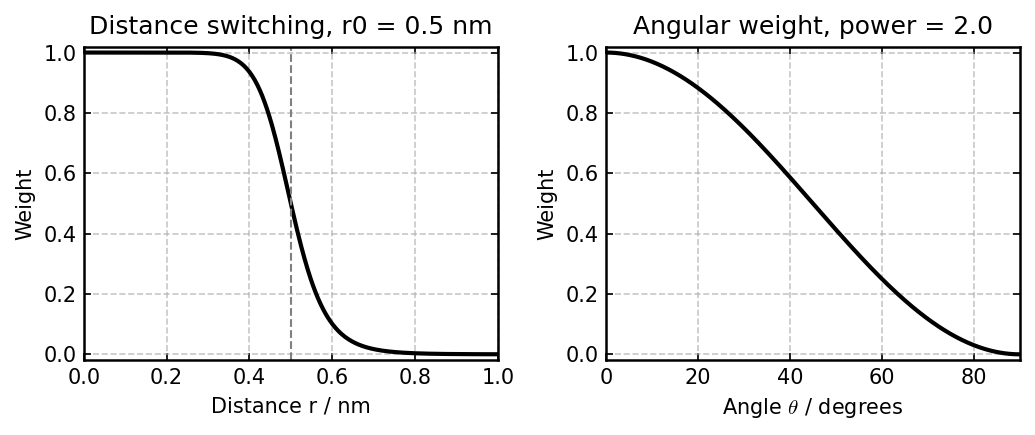

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Weighting functions
# -----------------------------
def switching(r, r_cut):
    """
    Smooth contact / distance weight.
    """
    x = r / r_cut
    return 1.0 / (1.0 + x**12)


def angular_weight(cos_theta, angular_power):
    """
    Directional/front-side angular weight.

    cos_theta is the cosine of the angle between N->H and H->heavy_atom.
    Only atoms in front of the amide H contribute.
    """
    return np.maximum(0.0, cos_theta) ** angular_power


# -----------------------------
# Parameters
# -----------------------------
r_cut = 0.5      # nm
angular_power = 2.0

# Distance switching: 0–1 nm
r = np.linspace(0, 1.0, 500)
w_r = switching(r, r_cut)

# Angular weighting: 0–90 degrees
theta_deg = np.linspace(0, 90, 500)
cos_theta = np.cos(np.deg2rad(theta_deg))
w_theta = angular_weight(cos_theta, angular_power)

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(7, 3))

# Distance switching
axes[0].plot(r, w_r, color='black')
axes[0].axvline(r_cut, color='gray', linestyle='--', linewidth=1)
axes[0].set_xlabel("Distance r / nm")
axes[0].set_ylabel("Weight")
axes[0].set_title(f"Distance switching, r0 = {r_cut} nm")
axes[0].set_xlim(0, 1.0)
axes[0].set_ylim(-0.02, 1.02)

# Angular weighting
axes[1].plot(theta_deg, w_theta, color='black')
axes[1].set_xlabel(r"Angle $\theta$ / degrees")
axes[1].set_ylabel("Weight")
axes[1].set_title(f"Angular weight, power = {angular_power}")
axes[1].set_xlim(0, 90)
axes[1].set_ylim(-0.02, 1.02)

plt.tight_layout()
plt.show()

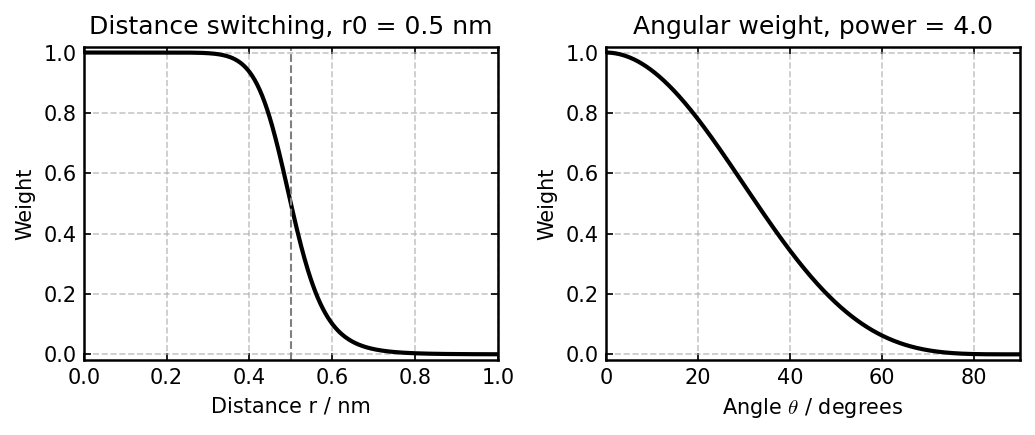

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Weighting functions
# -----------------------------
def switching(r, r_cut):
    """
    Smooth contact / distance weight.
    """
    x = r / r_cut
    return 1.0 / (1.0 + x**12)


def angular_weight(cos_theta, angular_power):
    """
    Directional/front-side angular weight.

    cos_theta is the cosine of the angle between N->H and H->heavy_atom.
    Only atoms in front of the amide H contribute.
    """
    return np.maximum(0.0, cos_theta) ** angular_power


# -----------------------------
# Parameters
# -----------------------------
r_cut = 0.5      # nm
angular_power = 4.0

# Distance switching: 0–1 nm
r = np.linspace(0, 1.0, 500)
w_r = switching(r, r_cut)

# Angular weighting: 0–90 degrees
theta_deg = np.linspace(0, 90, 500)
cos_theta = np.cos(np.deg2rad(theta_deg))
w_theta = angular_weight(cos_theta, angular_power)

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(7, 3))

# Distance switching
axes[0].plot(r, w_r, color='black')
axes[0].axvline(r_cut, color='gray', linestyle='--', linewidth=1)
axes[0].set_xlabel("Distance r / nm")
axes[0].set_ylabel("Weight")
axes[0].set_title(f"Distance switching, r0 = {r_cut} nm")
axes[0].set_xlim(0, 1.0)
axes[0].set_ylim(-0.02, 1.02)

# Angular weighting
axes[1].plot(theta_deg, w_theta, color='black')
axes[1].set_xlabel(r"Angle $\theta$ / degrees")
axes[1].set_ylabel("Weight")
axes[1].set_title(f"Angular weight, power = {angular_power}")
axes[1].set_xlim(0, 90)
axes[1].set_ylim(-0.02, 1.02)

plt.tight_layout()
plt.show()

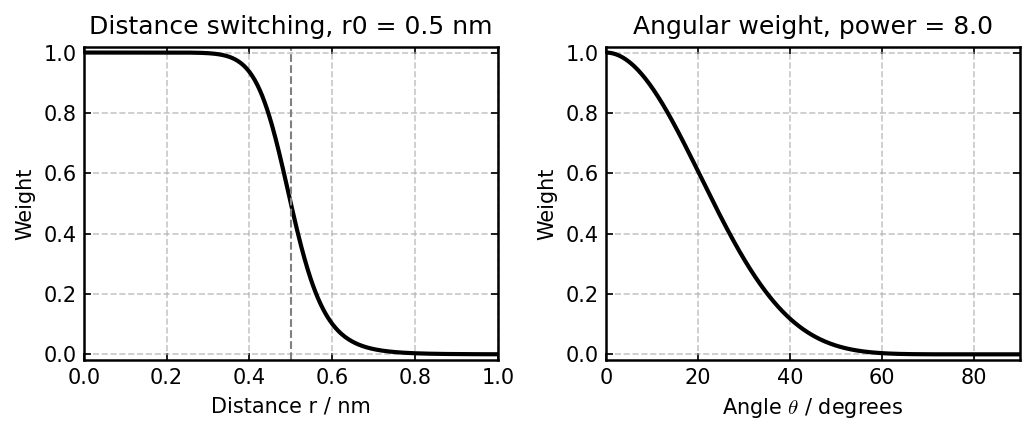

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Weighting functions
# -----------------------------
def switching(r, r_cut):
    """
    Smooth contact / distance weight.
    """
    x = r / r_cut
    return 1.0 / (1.0 + x**12)


def angular_weight(cos_theta, angular_power):
    """
    Directional/front-side angular weight.

    cos_theta is the cosine of the angle between N->H and H->heavy_atom.
    Only atoms in front of the amide H contribute.
    """
    return np.maximum(0.0, cos_theta) ** angular_power


# -----------------------------
# Parameters
# -----------------------------
r_cut = 0.5      # nm
angular_power = 8.0

# Distance switching: 0–1 nm
r = np.linspace(0, 1.0, 500)
w_r = switching(r, r_cut)

# Angular weighting: 0–90 degrees
theta_deg = np.linspace(0, 90, 500)
cos_theta = np.cos(np.deg2rad(theta_deg))
w_theta = angular_weight(cos_theta, angular_power)

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(7, 3))

# Distance switching
axes[0].plot(r, w_r, color='black')
axes[0].axvline(r_cut, color='gray', linestyle='--', linewidth=1)
axes[0].set_xlabel("Distance r / nm")
axes[0].set_ylabel("Weight")
axes[0].set_title(f"Distance switching, r0 = {r_cut} nm")
axes[0].set_xlim(0, 1.0)
axes[0].set_ylim(-0.02, 1.02)

# Angular weighting
axes[1].plot(theta_deg, w_theta, color='black')
axes[1].set_xlabel(r"Angle $\theta$ / degrees")
axes[1].set_ylabel("Weight")
axes[1].set_title(f"Angular weight, power = {angular_power}")
axes[1].set_xlim(0, 90)
axes[1].set_ylim(-0.02, 1.02)

plt.tight_layout()
plt.show()

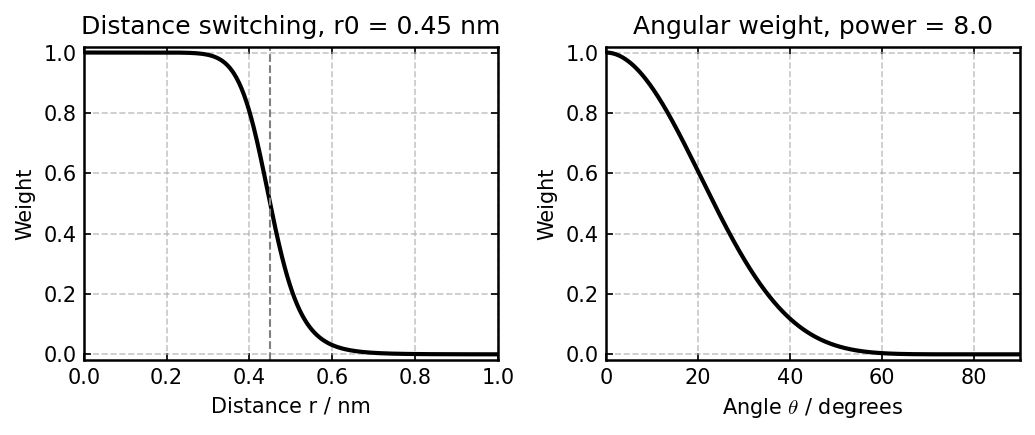

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Weighting functions
# -----------------------------
def switching(r, r_cut):
    """
    Smooth contact / distance weight.
    """
    x = r / r_cut
    return 1.0 / (1.0 + x**12)


def angular_weight(cos_theta, angular_power):
    """
    Directional/front-side angular weight.

    cos_theta is the cosine of the angle between N->H and H->heavy_atom.
    Only atoms in front of the amide H contribute.
    """
    return np.maximum(0.0, cos_theta) ** angular_power


# -----------------------------
# Parameters
# -----------------------------
r_cut = 0.45      # nm
angular_power = 8.0

# Distance switching: 0–1 nm
r = np.linspace(0, 1.0, 500)
w_r = switching(r, r_cut)

# Angular weighting: 0–90 degrees
theta_deg = np.linspace(0, 90, 500)
cos_theta = np.cos(np.deg2rad(theta_deg))
w_theta = angular_weight(cos_theta, angular_power)

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(7, 3))

# Distance switching
axes[0].plot(r, w_r, color='black')
axes[0].axvline(r_cut, color='gray', linestyle='--', linewidth=1)
axes[0].set_xlabel("Distance r / nm")
axes[0].set_ylabel("Weight")
axes[0].set_title(f"Distance switching, r0 = {r_cut} nm")
axes[0].set_xlim(0, 1.0)
axes[0].set_ylim(-0.02, 1.02)

# Angular weighting
axes[1].plot(theta_deg, w_theta, color='black')
axes[1].set_xlabel(r"Angle $\theta$ / degrees")
axes[1].set_ylabel("Weight")
axes[1].set_title(f"Angular weight, power = {angular_power}")
axes[1].set_xlim(0, 90)
axes[1].set_ylim(-0.02, 1.02)

plt.tight_layout()
plt.show()

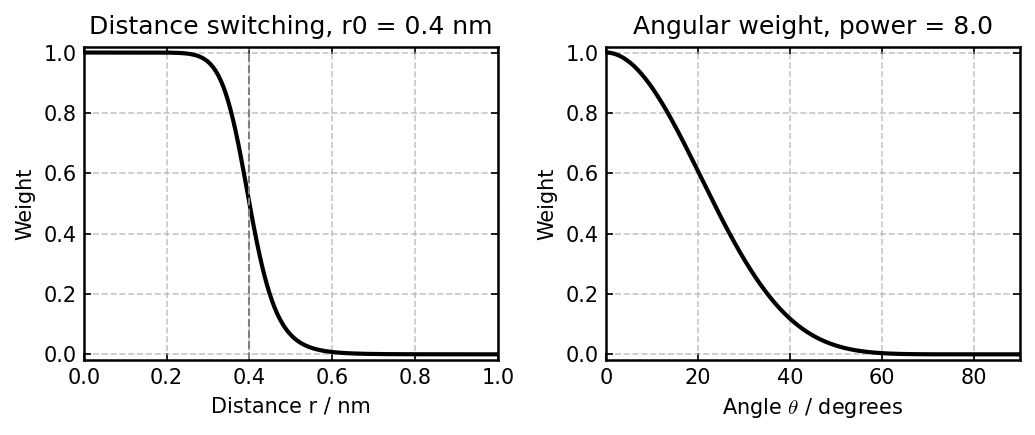

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Weighting functions
# -----------------------------
def switching(r, r_cut):
    """
    Smooth contact / distance weight.
    """
    x = r / r_cut
    return 1.0 / (1.0 + x**12)


def angular_weight(cos_theta, angular_power):
    """
    Directional/front-side angular weight.

    cos_theta is the cosine of the angle between N->H and H->heavy_atom.
    Only atoms in front of the amide H contribute.
    """
    return np.maximum(0.0, cos_theta) ** angular_power


# -----------------------------
# Parameters
# -----------------------------
r_cut = 0.4      # nm
angular_power = 8.0

# Distance switching: 0–1 nm
r = np.linspace(0, 1.0, 500)
w_r = switching(r, r_cut)

# Angular weighting: 0–90 degrees
theta_deg = np.linspace(0, 90, 500)
cos_theta = np.cos(np.deg2rad(theta_deg))
w_theta = angular_weight(cos_theta, angular_power)

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(7, 3))

# Distance switching
axes[0].plot(r, w_r, color='black')
axes[0].axvline(r_cut, color='gray', linestyle='--', linewidth=1)
axes[0].set_xlabel("Distance r / nm")
axes[0].set_ylabel("Weight")
axes[0].set_title(f"Distance switching, r0 = {r_cut} nm")
axes[0].set_xlim(0, 1.0)
axes[0].set_ylim(-0.02, 1.02)

# Angular weighting
axes[1].plot(theta_deg, w_theta, color='black')
axes[1].set_xlabel(r"Angle $\theta$ / degrees")
axes[1].set_ylabel("Weight")
axes[1].set_title(f"Angular weight, power = {angular_power}")
axes[1].set_xlim(0, 90)
axes[1].set_ylim(-0.02, 1.02)

plt.tight_layout()
plt.show()

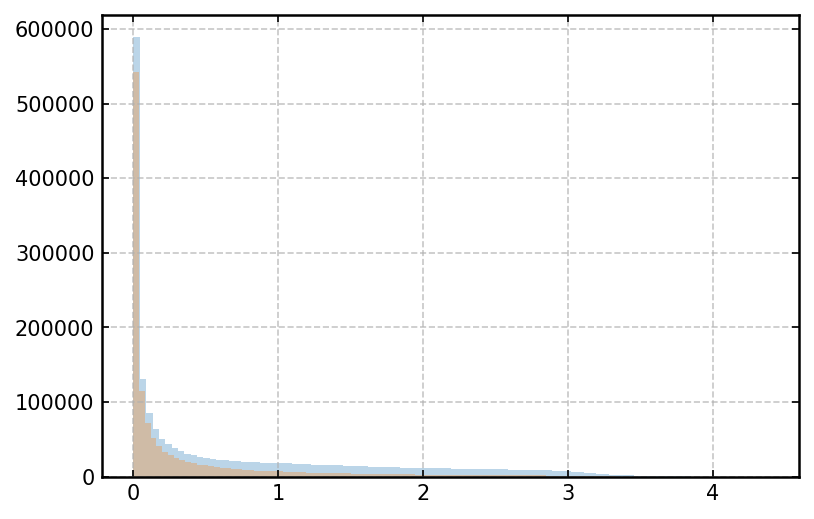

In [22]:
# check ACTR data

fopen = np.load('../../MD_DATA/ACTR/rewM10/fopen.npy')
rho = np.load('../../MD_DATA/ACTR/rho_front_neigh4/rho_front_frames.npy')

plt.hist(rho.flatten(), bins=100, alpha=0.3)
plt.hist(rho.flatten()[fopen.flatten()>0], bins=100, alpha=0.3)
plt.show()

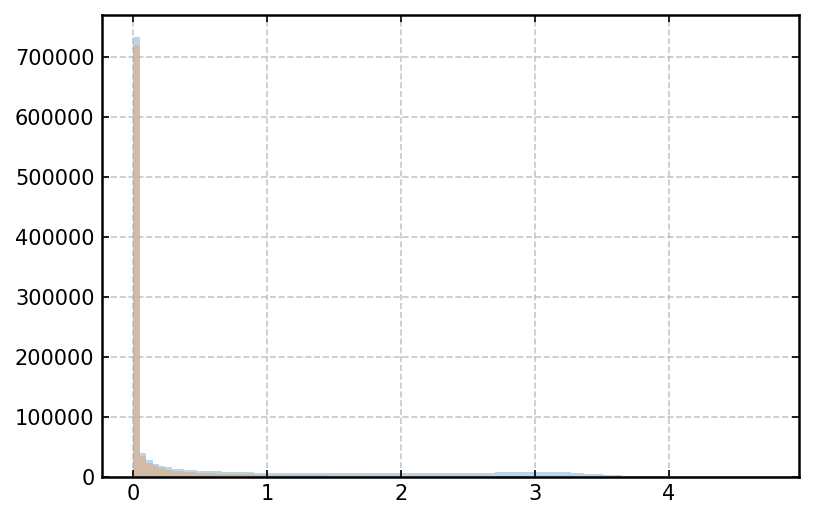

In [18]:
# check ACTR data

fopen = np.load('../../MD_DATA/aSyn/rewM10/fopen.npy')
rho = np.load('../../MD_DATA/aSyn/rho_front_neigh4/rho_front_frames.npy')

plt.hist(rho.flatten(), bins=100, alpha=0.3)
plt.hist(rho.flatten()[fopen.flatten()>0], bins=100, alpha=0.3)
plt.show()